# TP 4 — KNN : reconnaître des chiffres manuscrits

---
## Contexte et objectif du TP
On veut qu'une machine **lise des chiffres écrits à la main** (codes postaux, chèques…). Le jeu de données (UCI, 1998)
contient **1 797 images** de chiffres écrits par 43 personnes, réduites à **8 × 8 pixels**.

L'algorithme utilisé est **KNN** (*k nearest neighbors*, « k plus proches voisins »), le plus intuitif qui soit :
*« dis-moi à qui tu ressembles »*. Pour classer une nouvelle image :
1. on calcule sa **distance** à toutes les images d'entraînement ;
2. on garde les **k plus proches** ;
3. on prédit la **classe majoritaire** parmi ces k voisins (vote).

Il n'y a **pas d'apprentissage à proprement parler** : le « modèle », c'est simplement la **mémoire des exemples**.

Ce TP a pour but de :
1. comprendre qu'**une image = un vecteur de nombres** (les pixels) ;
2. **programmer KNN à la main** puis le comparer à scikit-learn ;
3. **choisir k** (et d'autres réglages) par **validation croisée**, sans tricher avec le jeu de test ;
4. **analyser les erreurs** du modèle ;
5. refaire l'expérience avec **Orange**.

| Partie | Contenu | Points |
|---|---|---|
| **A** | Des images aux nombres | 3 |
| **B** | KNN avec Python | 13 |
| **C** | KNN avec Orange | 4 |

##  Livrables
Ce notebook exécuté (`.ipynb`) et le fichier Orange (`.ows`).

## 📖 Mini-glossaire
| Terme | Signification | Pourquoi on en a besoin |
|---|---|---|
| **Importation** | Charger les bibliothèques et le fichier | Point de départ |
| **Exploration / Visualisation** | Compter, afficher les images, tracer des courbes | Comprendre les données avant de modéliser |
| **Pixel / vecteur** | Une image 8×8 = 64 nombres (intensité de 0 à 16) mis « à plat » sur une ligne | Un algorithme travaille sur des nombres, pas sur des images |
| **Distance euclidienne** | √(Σ (aᵢ − bᵢ)²) : « à vol d'oiseau » entre deux vecteurs | Mesurer à quel point deux images se ressemblent |
| **Distance de Manhattan** | Σ \|aᵢ − bᵢ\| : somme des écarts, « en suivant les rues » | Autre façon de mesurer la ressemblance (paramètre `p=1`) |
| **Séparation (train/test)** | 75 % pour l'entraînement (la mémoire), 25 % gardés pour le test | Évaluer sur des images jamais vues |
| **Modèle naïf (baseline)** | Prédire toujours la classe la plus fréquente | Savoir si notre modèle apporte vraiment quelque chose |
| **Hyperparamètre** | Réglage choisi **avant** l'entraînement (k, métrique, poids) | Il change la qualité du modèle |
| **Validation croisée (CV)** | Découper le train en 5 plis ; on teste 5 fois sur un pli différent | Estimer la qualité et choisir les réglages **sans toucher au test** |
| **GridSearchCV** | Essaie automatiquement toutes les combinaisons d'hyperparamètres avec la CV | Trouver le meilleur réglage proprement |
| **Matrice de confusion** | Tableau « vrai chiffre × chiffre prédit » | Voir **quelles** erreurs sont commises |

## 0. Importation des bibliothèques et du fichier

**Importation** : `numpy` (calcul sur les vecteurs), `pandas` (tableaux), `matplotlib` (images et courbes),
et de `scikit-learn` : le KNN, le découpage train/test, la validation croisée, `GridSearchCV` et les métriques.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Bibliothèques importées ✅")

Bibliothèques importées ✅


**Importation du fichier** : sur Colab, il faut envoyer `chiffres.csv` depuis votre ordinateur
(en Jupyter local, placez-le dans le même dossier que le notebook).

---
# PARTIE A — Des images aux nombres · 
**But** : comprendre qu'une image n'est qu'un **tableau de nombres**, et regarder à quoi ressemblent nos données.

## A.1 — Découvrir
### Importation et exploration
*Pourquoi ?* Vérifier la taille du jeu (1 797 lignes × 65 colonnes : 64 pixels + la cible) et la répartition des chiffres.

In [3]:
df = pd.read_csv("chiffres.csv")                      # importation
print("Dimensions :", df.shape)
display(df.head())

CIBLE = "chiffre"                                     # ⚠️ adapter si la colonne cible s'appelle autrement
COLS_PIXELS = [c for c in df.columns if c != CIBLE]  # px0 ... px63
print("Nombre de colonnes de pixels :", len(COLS_PIXELS))
print("Valeurs des pixels : min =", df[COLS_PIXELS].min().min(), "| max =", df[COLS_PIXELS].max().max())
print("Valeurs manquantes :", int(df.isna().sum().sum()))

Dimensions : (1797, 65)


,px0,px1,px2,px3,px4,px5,px6,px7,px8,px9,...,px55,px56,px57,px58,px59,px60,px61,px62,px63,chiffre
0,0,0,5,13,9,1,0,0,0,0,...,0,0,0,6,13,10,0,0,0,0
1,0,0,0,12,13,5,0,0,0,0,...,0,0,0,0,11,16,10,0,0,1
2,0,0,0,4,15,12,0,0,0,0,...,0,0,0,0,3,11,16,9,0,2
3,0,0,7,15,13,1,0,0,0,8,...,0,0,0,7,13,13,9,0,0,3
4,0,0,0,1,11,0,0,0,0,0,...,0,0,0,0,2,16,4,0,0,4


Nombre de colonnes de pixels : 64
Valeurs des pixels : min = 0 | max = 16
Valeurs manquantes : 0


### Nombre d'images par chiffre (visualisation)

chiffre
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


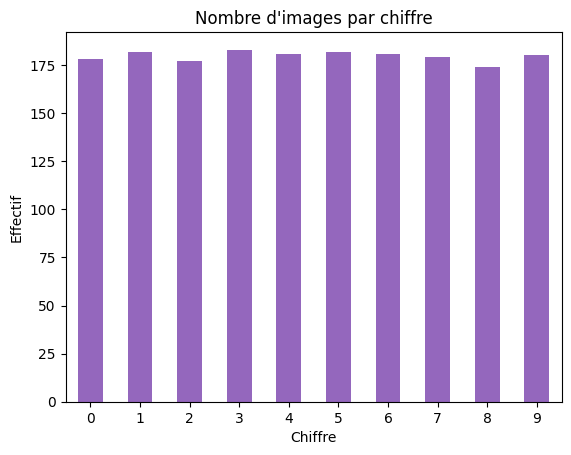

In [4]:
comptes = df[CIBLE].value_counts().sort_index()
print(comptes)

comptes.plot(kind="bar", rot=0, color="tab:purple")
plt.title("Nombre d'images par chiffre")
plt.xlabel("Chiffre"); plt.ylabel("Effectif")
plt.show()

### Afficher les 10 premières images
Chaque ligne contient **64 valeurs** « ligne par ligne ». Pour la voir comme une image, on la **remet en carré 8 × 8**
avec `reshape(8, 8)`, puis `imshow(..., cmap="gray_r")` (gris inversé : pixel fort = encre foncée).
*Pourquoi ?* Vérifier de ses propres yeux que les nombres représentent bien des chiffres.

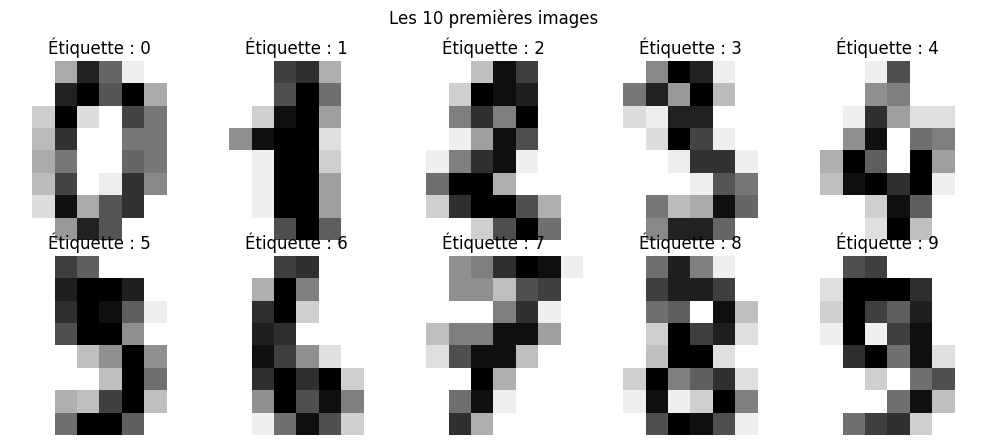

In [5]:
X = df[COLS_PIXELS].values        # tableau numpy (1797, 64)
y = df[CIBLE].values              # vrais chiffres

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Étiquette : {y[i]}")
    ax.axis("off")
plt.suptitle("Les 10 premières images")
plt.tight_layout()
plt.show()

✍️ **Ma réponse A.1** : nombre d'images par chiffre = *(recopier ; le jeu est-il équilibré ?)* ;
une image = un vecteur de *(64)* nombres compris entre *(0 et 16)*.

## A.2 — Une image moyenne
Pour chaque chiffre, on calcule la **moyenne pixel par pixel** de toutes ses images : on obtient l'« image type » du chiffre.
*Pourquoi ?* Voir ce qui distingue les chiffres entre eux, et repérer des **pixels inutiles** (toujours à 0 : ils n'apportent
aucune information et n'influencent pas les distances).

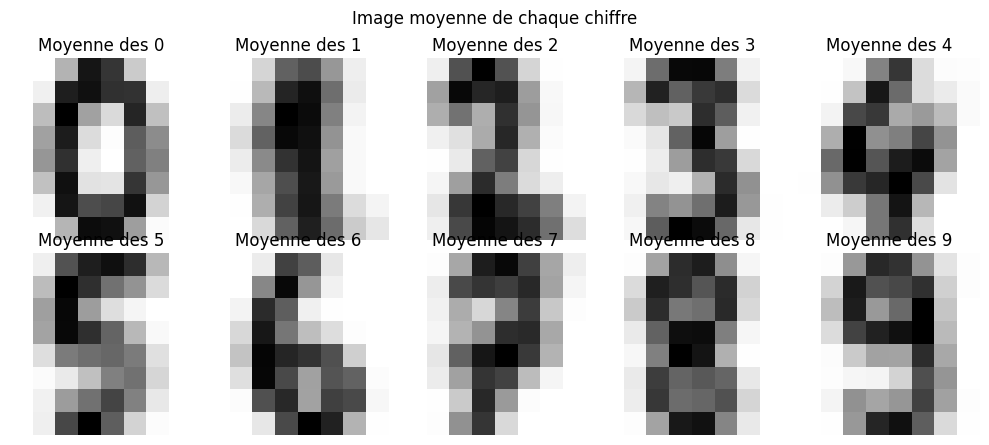

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for chiffre, ax in zip(range(10), axes.ravel()):
    moyenne = X[y == chiffre].mean(axis=0)            # moyenne pixel par pixel des images de ce chiffre
    ax.imshow(moyenne.reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Moyenne des {chiffre}")
    ax.axis("off")
plt.suptitle("Image moyenne de chaque chiffre")
plt.tight_layout()
plt.show()

**Pixels qui ne servent jamais** (valeur 0 dans toutes les images) :

Indices des pixels toujours à 0 : [ 0 32 39]
Noms : ['px0', 'px32', 'px39']


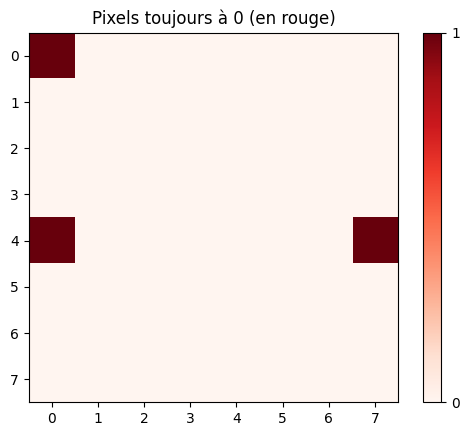

In [7]:
jamais_utilises = np.where(X.max(axis=0) == 0)[0]
print("Indices des pixels toujours à 0 :", jamais_utilises)
print("Noms :", [COLS_PIXELS[i] for i in jamais_utilises])

masque = (X.max(axis=0) == 0).reshape(8, 8)
plt.imshow(masque, cmap="Reds")
plt.title("Pixels toujours à 0 (en rouge)")
plt.colorbar(ticks=[0, 1])
plt.show()

✍️ **Ma réponse A.2** : pixels toujours à 0 = *(liste, par ex. px0, px32, px39… : souvent les coins, car les chiffres
sont écrits au centre de l'image)*. Observations sur les images moyennes : *(quels chiffres se ressemblent le plus ?)*

---
# PARTIE B — KNN avec Python · 

## B.1 — KNN à la main
### Séparation train / test (75 % / 25 %)
* **Train (75 %)** : la « mémoire » du KNN (les exemples connus).
* **Test (25 %)** : mis de côté pour évaluer honnêtement le modèle sur des images **jamais vues**.
* `stratify=y` : même proportion de chaque chiffre dans les deux jeux ; `random_state=42` : découpe reproductible.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (1347, 64) | Test : (450, 64)


### Les 4 étapes de KNN, pour **une seule image** (la première du test)
1. **Distance euclidienne** de cette image à **toutes** les images d'entraînement (avec `numpy`).
2. **Trier** et garder les **5 plus proches**.
3. **Afficher leurs étiquettes**.
4. **Voter** : la classe la plus fréquente gagne.

*Pourquoi le faire à la main ?* Pour comprendre qu'il n'y a rien de magique : KNN, c'est seulement « chercher les plus ressemblants ».

In [9]:
K = 5
x0 = X_test[0]                                              # première image du test

# 1) distance euclidienne à toutes les images d'entraînement : racine de la somme des carrés des écarts
distances = np.sqrt(((X_train - x0) ** 2).sum(axis=1))

# 2) indices des K plus proches
idx_voisins = np.argsort(distances)[:K]

# 3) leurs étiquettes et leurs distances
etiquettes = y_train[idx_voisins]
print("Distances des 5 plus proches :", distances[idx_voisins].round(2))
print("Étiquettes des 5 plus proches :", etiquettes)

# 4) vote majoritaire
vote = Counter(etiquettes).most_common(1)[0][0]
print(f"\nVote : {Counter(etiquettes)}  ->  prédiction à la main = {vote}")
print("Vraie étiquette de cette image :", y_test[0])

Distances des 5 plus proches : [18.55 20.1  20.17 20.35 20.52]
Étiquettes des 5 plus proches : [1 1 1 1 1]

Vote : Counter({np.int64(1): 5})  ->  prédiction à la main = 1
Vraie étiquette de cette image : 1


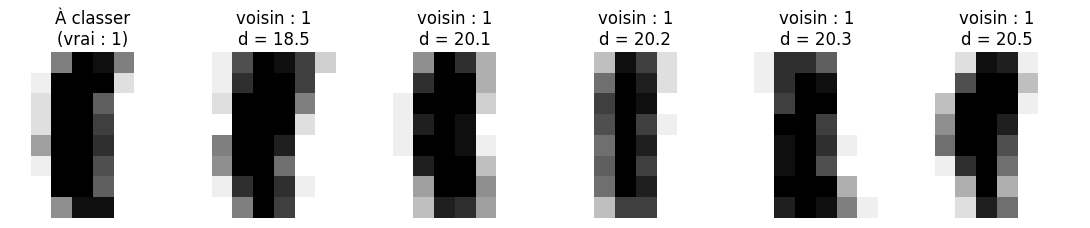

In [10]:
# Visualisation : l'image à classer et ses 5 voisins
fig, axes = plt.subplots(1, K + 1, figsize=(11, 2.6))
axes[0].imshow(x0.reshape(8, 8), cmap="gray_r"); axes[0].set_title(f"À classer\n(vrai : {y_test[0]})")
for ax, i in zip(axes[1:], idx_voisins):
    ax.imshow(X_train[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"voisin : {y_train[i]}\nd = {distances[i]:.1f}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### Vérification avec scikit-learn

In [11]:
knn5 = KNeighborsClassifier(n_neighbors=5)
knn5.fit(X_train, y_train)                 # "fit" = simplement mémoriser les exemples
pred_sklearn = knn5.predict(x0.reshape(1, -1))[0]
print("Prédiction scikit-learn :", pred_sklearn, "| à la main :", vote, "| identiques :", pred_sklearn == vote)

Prédiction scikit-learn : 1 | à la main : 1 | identiques : True


✍️ **Ma réponse B.1** : étiquettes des 5 voisins = *(…)* ; vote = *(…)* ; vérification scikit-learn : *(identique ?)*.

## B.2 — Premier score
### Entraînement et test
Pour KNN, `fit` ne fait que **mémoriser** les exemples d'entraînement. L'essentiel du travail a lieu à la **prédiction**
(calcul des distances). On mesure l'**accuracy** (part de bonnes réponses) sur le **test**.

### Comparaison avec un modèle naïf
Le **modèle naïf** répond toujours le chiffre le plus fréquent. *Pourquoi ?* C'est le « score plancher » :
si notre modèle ne bat pas franchement ce score, il ne sert à rien.

In [12]:
knn5 = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
acc_knn = accuracy_score(y_test, knn5.predict(X_test))

naif = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
acc_naif = accuracy_score(y_test, naif.predict(X_test))

print(f"Accuracy KNN (k=5) sur le test : {acc_knn:.4f}")
print(f"Accuracy modèle naïf           : {acc_naif:.4f}  (répond toujours « {naif.predict(X_test[:1])[0]} »)")
print(f"Gain par rapport au naïf       : +{(acc_knn - acc_naif) * 100:.1f} points")

Accuracy KNN (k=5) sur le test : 0.9844
Accuracy modèle naïf           : 0.1022  (répond toujours « 3 »)
Gain par rapport au naïf       : +88.2 points


✍️ **Ma réponse B.2** : accuracy KNN = *(…)* ; modèle naïf = *(≈ 10 %, car 10 chiffres à peu près équilibrés)* ;
KNN est donc *(…)* fois meilleur que le hasard organisé.

## B.3 — Choisir k
**Question** : combien de voisins faut-il consulter ?
* k **petit** (ex. 1) : très sensible au bruit (un seul voisin trompeur suffit) → risque de **surapprentissage**.
* k **grand** : on vote avec des voisins de plus en plus lointains et différents → le modèle devient trop « flou »
  (**sous-apprentissage**) ; à l'extrême (k = taille du train), il prédit toujours la classe majoritaire.

### Validation croisée à 5 plis, **sur le train uniquement**
On coupe le train en 5 morceaux ; on entraîne sur 4 et on teste sur le 5ᵉ, **5 fois**, puis on fait la moyenne.
*Pourquoi sur le train ?* Voir la question de fin de partie.

,k,accuracy_CV5
0,1,0.9911
1,2,0.9844
2,3,0.9881
3,4,0.9814
4,5,0.9852
5,6,0.9829
6,7,0.9829
7,8,0.9777
8,9,0.9807
9,10,0.9770


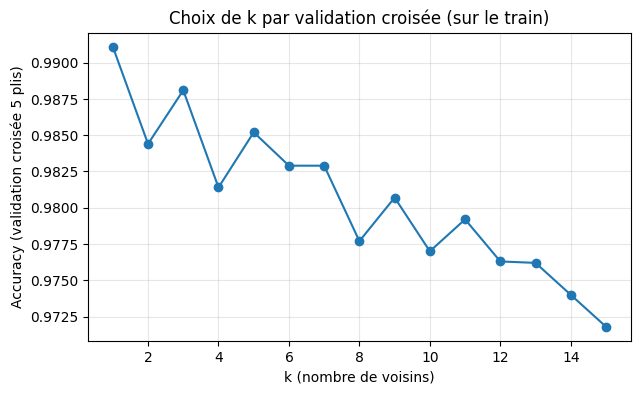

Meilleur k selon la CV : 1


In [13]:
valeurs_k = range(1, 16)
scores_cv = []
for k in valeurs_k:
    m = KNeighborsClassifier(n_neighbors=k)
    scores_cv.append(cross_val_score(m, X_train, y_train, cv=5, scoring="accuracy").mean())

res_k = pd.DataFrame({"k": list(valeurs_k), "accuracy_CV5": np.round(scores_cv, 4)})
display(res_k)

plt.figure(figsize=(7, 4))
plt.plot(res_k["k"], res_k["accuracy_CV5"], marker="o")
plt.xlabel("k (nombre de voisins)"); plt.ylabel("Accuracy (validation croisée 5 plis)")
plt.title("Choix de k par validation croisée (sur le train)")
plt.grid(alpha=0.3)
plt.show()

k_best = int(res_k.loc[res_k["accuracy_CV5"].idxmax(), "k"])
print("Meilleur k selon la CV :", k_best)

**Bonus : que se passe-t-il pour k très grand ?** On pousse k bien au-delà de 15 pour voir la dégradation.

In [14]:
for k in (1, 5, 15, 50, 200, 600, 1000):
    m = KNeighborsClassifier(n_neighbors=k)
    s = cross_val_score(m, X_train, y_train, cv=5).mean()
    print(f"k = {k:5d}  ->  accuracy CV ≈ {s:.3f}")
print("\n(Plus k grandit, plus le vote inclut tout le monde : le modèle tend vers la classe majoritaire, donc vers le modèle naïf.)")

k =     1  ->  accuracy CV ≈ 0.991
k =     5  ->  accuracy CV ≈ 0.985
k =    15  ->  accuracy CV ≈ 0.972
k =    50  ->  accuracy CV ≈ 0.939
k =   200  ->  accuracy CV ≈ 0.866
k =   600  ->  accuracy CV ≈ 0.610
k =  1000  ->  accuracy CV ≈ 0.239

(Plus k grandit, plus le vote inclut tout le monde : le modèle tend vers la classe majoritaire, donc vers le modèle naïf.)


✍️ **Ma réponse B.3** :
* Meilleur k : *(…)* avec une accuracy CV de *(…)*.
* **Que se passe-t-il pour k très grand ?** L'accuracy **chute** : le vote inclut des voisins éloignés, donc de chiffres
  différents ; à la limite (k = taille du train) le modèle répond toujours la classe la plus fréquente (≈ modèle naïf) : c'est du **sous-apprentissage**.
* **Pourquoi ne faut-il pas choisir k sur le test ?** Si on choisit k en regardant le score du test, le test a « participé » au
  choix : il n'est plus indépendant et l'accuracy finale est **trop optimiste** (fuite d'information, *data leakage*). Le test doit
  rester intact jusqu'à l'évaluation finale ; les réglages se font par validation croisée **sur le train**.

## B.4 — Réglages avec `GridSearchCV`
On cherche **le meilleur couple de réglages** (hyperparamètres) :
* `n_neighbors` ∈ {1, 3, 5, 7} ;
* `weights` ∈ {`uniform` (tous les voisins pèsent pareil), `distance` (les plus proches pèsent plus)} ;
* `p` ∈ {1 (distance de Manhattan), 2 (euclidienne)}.

`GridSearchCV` essaie les 4 × 2 × 2 = **16 combinaisons**, chacune évaluée en **validation croisée 5 plis sur le train**,
et retient la meilleure. Ensuite, le modèle retenu est évalué **une seule fois** sur le test.

In [15]:
grille = {
    "n_neighbors": [1, 3, 5, 7],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}
gs = GridSearchCV(KNeighborsClassifier(), grille, cv=5, scoring="accuracy")
gs.fit(X_train, y_train)                    # ENTRAÎNEMENT : 16 combinaisons x 5 plis

print("Meilleurs paramètres :", gs.best_params_)
print(f"Meilleure accuracy CV (train) : {gs.best_score_:.4f}")

# Top 5 des combinaisons
cv_res = pd.DataFrame(gs.cv_results_)[["param_n_neighbors", "param_weights", "param_p", "mean_test_score", "rank_test_score"]]
display(cv_res.sort_values("rank_test_score").head(5))

Meilleurs paramètres : {'n_neighbors': 1, 'p': 2, 'weights': 'uniform'}
Meilleure accuracy CV (train) : 0.9911


,param_n_neighbors,param_weights,param_p,mean_test_score,rank_test_score
3,1,distance,2,0.991095,1
2,1,uniform,2,0.991095,1
6,3,uniform,2,0.988126,3
7,3,distance,2,0.987383,4
15,7,distance,2,0.985158,5


### Évaluation finale (une seule fois) sur le test

In [16]:
modele = gs.best_estimator_                 # déjà ré-entraîné sur tout le train
y_pred = modele.predict(X_test)
acc_final = accuracy_score(y_test, y_pred)
print(f"Accuracy FINALE sur le test = {acc_final:.4f}")
print(f"(rappel : KNN k=5 simple = {acc_knn:.4f} | modèle naïf = {acc_naif:.4f})")

Accuracy FINALE sur le test = 0.9844
(rappel : KNN k=5 simple = 0.9844 | modèle naïf = 0.1022)


✍️ **Ma réponse B.4** : meilleur couple = *(n_neighbors = …, weights = …, p = …)* ; accuracy CV = *(…)* ; accuracy test = *(…)*.
Le test n'est utilisé **qu'une fois**, pour ne pas biaiser le résultat.

## B.5 — Les erreurs
Une bonne accuracy ne dit pas **où** le modèle se trompe. La **matrice de confusion** croise le vrai chiffre (lignes) et le
chiffre prédit (colonnes) : la diagonale = bonnes réponses, hors diagonale = confusions.

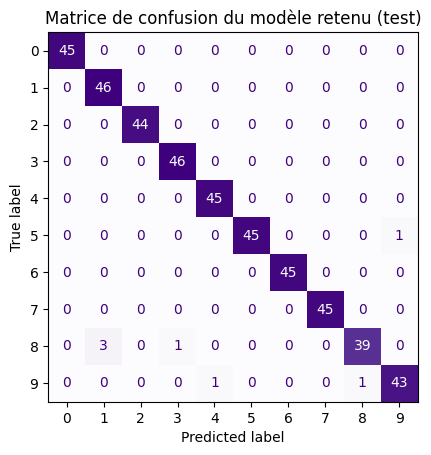

Confusions les plus fréquentes (vrai -> prédit : nombre) :
   8 -> 1 : 3
   5 -> 9 : 1
   8 -> 3 : 1
   9 -> 4 : 1
   9 -> 8 : 1

Nombre total d'erreurs : 7 sur 450 images


In [17]:
cm = confusion_matrix(y_test, y_pred, labels=range(10))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(cmap="Purples", colorbar=False)
plt.title("Matrice de confusion du modèle retenu (test)")
plt.show()

# Confusions les plus fréquentes (hors diagonale)
confusions = [(i, j, cm[i, j]) for i in range(10) for j in range(10) if i != j and cm[i, j] > 0]
confusions.sort(key=lambda t: -t[2])
print("Confusions les plus fréquentes (vrai -> prédit : nombre) :")
for vrai, pred, n in confusions[:8]:
    print(f"   {vrai} -> {pred} : {n}")
print(f"\nNombre total d'erreurs : {(y_pred != y_test).sum()} sur {len(y_test)} images")

### Les images mal classées

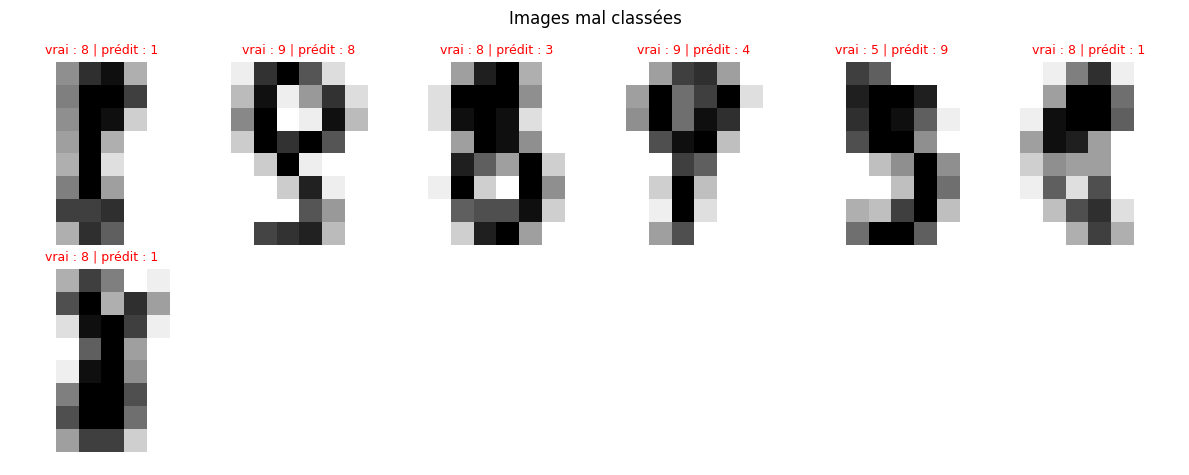

In [18]:
idx_err = np.where(y_pred != y_test)[0]
n_aff = min(len(idx_err), 12)

if n_aff == 0:
    print("Aucune erreur sur le test 🎉")
else:
    cols = 6
    lignes = int(np.ceil(n_aff / cols))
    fig, axes = plt.subplots(lignes, cols, figsize=(2 * cols, 2.4 * lignes))
    axes = np.atleast_1d(axes).ravel()
    for ax, i in zip(axes, idx_err[:n_aff]):
        ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"vrai : {y_test[i]} | prédit : {y_pred[i]}", fontsize=9, color="red")
    for ax in axes:
        ax.axis("off")
    plt.suptitle("Images mal classées")
    plt.tight_layout(); plt.show()

✍️ **Ma réponse B.5** : confusions les plus fréquentes = *(ex. 8→1, 4→9, 3→5, 7→9… à recopier depuis vos résultats)* ;
elles s'expliquent par *(formes proches une fois réduites à 8×8 pixels)*.
**Auriez-vous fait mieux ?** *(regarder les images mal classées : certaines sont ambiguës même pour un humain,
d'autres sont lisibles → limite de KNN, qui compare pixel à pixel sans « comprendre » la forme)*.

---
# PARTIE C — Avec Orange · *4 points*
**But** : refaire l'expérience avec un outil visuel, sans code.

### Workflow Orange à construire
`File (chiffres.csv) → kNN` puis `File + kNN → Test and Score → Confusion Matrix → Data Table`

| Étape | Widget | Réglages et pourquoi |
|---|---|---|
| 1 | **File** | Ouvrir `chiffres.csv`. Dans le tableau des colonnes, changer le **type** de `chiffre` en **categorical** et son **rôle** en **target** (Orange le voit d'abord comme un nombre ; or un chiffre est ici une *classe*, pas une quantité) |
| 2 | **kNN** | **5 voisins**, métrique **euclidienne**, poids **uniformes** |
| 3 | **Test and Score** | **Cross validation, 10 plis** ; relever **CA**. Essayer **1, 3, 7 voisins** et la métrique **Manhattan** |
| 4 | **Confusion Matrix** | Repérer les confusions ; cliquer sur une case puis brancher **Data Table** pour voir les images concernées |

👉 Enregistrer en **`.ows`** (Fichier → Enregistrer) : c'est un livrable.

### Vérification en Python (validation croisée à 10 plis sur tout le jeu)
Orange évalue sur **tout** le jeu de données en validation croisée 10 plis. Cette cellule reproduit la même idée
(de petites différences sont normales : découpage des plis ; **dans le rapport, on cite les valeurs d'Orange**).

In [19]:
lignes = []
for p, nom in ((2, "euclidienne"), (1, "Manhattan")):
    for k in (1, 3, 5, 7):
        m = KNeighborsClassifier(n_neighbors=k, p=p, weights="uniform")
        ca = cross_val_score(m, X, y, cv=10, scoring="accuracy").mean()
        lignes.append((nom, k, round(ca, 4)))
display(pd.DataFrame(lignes, columns=["métrique", "k", "CA (Python, CV 10 plis)"]))

,métrique,k,"CA (Python, CV 10 plis)"
0,euclidienne,1,0.9750
1,euclidienne,3,0.9766
2,euclidienne,5,0.9711
3,euclidienne,7,0.9677
4,Manhattan,1,0.9649
5,Manhattan,3,0.9661
6,Manhattan,5,0.9633
7,Manhattan,7,0.9594


✍️ **Ma réponse C** *(valeurs lues dans Orange)* :

| Métrique | k = 1 | k = 3 | k = 5 | k = 7 |
|---|---|---|---|---|
| Euclidienne | | | | |
| Manhattan | | | | |

* Meilleure configuration dans Orange : *(…)* — est-elle la même qu'en B.4 ? *(…)*
* Confusions retrouvées dans la matrice de confusion d'Orange : *(…)* — correspondent-elles à celles de B.5 ? *(…)*
* En cliquant sur une case de la matrice et avec **Data Table**, on a vu *(…)*.

---
#  Conclusion générale
* **Une image est un vecteur de pixels** : on peut donc lui appliquer n'importe quel algorithme sur des nombres.
* **KNN** classe un exemple d'après ses **k plus proches voisins** ; il ne « s'entraîne » pas, il **mémorise**.
* **Le choix de k** se fait par **validation croisée sur le train** : trop petit → sensible au bruit, trop grand → trop flou.
  **Le test ne sert qu'une fois**, à la fin.
* **L'accuracy ne suffit pas** : la matrice de confusion et les images mal classées montrent **quels chiffres se confondent**.
* **Limites** : KNN est lent à la prédiction (distances à tous les exemples) et compare pixel à pixel (sensible aux décalages).

